# Women's Clothing E-Commerce Reviews: EDA & Preprocessing

In [5]:
import json
import re
import warnings
from pathlib import Path

import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.0)

DATA_PATH = Path("Womens Clothing E-Commerce Reviews.csv")
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
OUT_DIR = Path("outputs"); OUT_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42
results = {}  # numbers collected here are reused in the report


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()

## 1. Load the data and first look

In [6]:
df_raw = pd.read_csv(DATA_PATH)
print("Shape:", df_raw.shape)
print(df_raw.dtypes)
print(df_raw.head())
results["raw_shape"] = list(df_raw.shape)

Shape: (23486, 11)
Unnamed: 0                 int64
Clothing ID                int64
Age                        int64
Title                        str
Review Text                  str
Rating                     int64
Recommended IND            int64
Positive Feedback Count    int64
Division Name                str
Department Name              str
Class Name                   str
dtype: object
   Unnamed: 0  Clothing ID  Age                    Title  \
0           0          767   33                      NaN   
1           1         1080   34                      NaN   
2           2         1077   60  Some major design flaws   
3           3         1049   50         My favorite buy!   
4           4          847   47         Flattering shirt   

                                         Review Text  Rating  Recommended IND  \
0  Absolutely wonderful - silky and sexy and comf...       4                1   
1  Love this dress!  it's sooo pretty.  i happene...       5                1   


## 2. Data quality checks (missing values and duplicates)

                 missing  percent
Title               3810    16.22
Review Text          845     3.60
Division Name         14     0.06
Department Name       14     0.06
Class Name            14     0.06
Duplicate rows (ignoring index column): 21


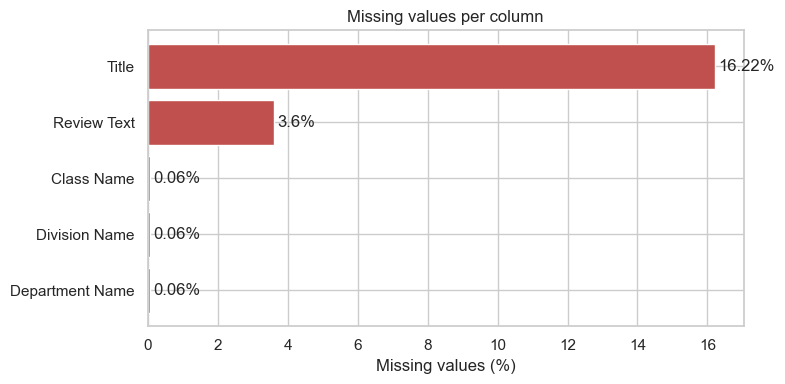

In [15]:
missing = df_raw.isna().sum()
missing_pct = (missing / len(df_raw) * 100).round(2)
miss_df = pd.DataFrame({"missing": missing, "percent": missing_pct})
print(miss_df[miss_df.missing > 0])
results["missing"] = miss_df[miss_df.missing > 0].to_dict("index")

dup_cols = [c for c in df_raw.columns if c != "Unnamed: 0"]
n_dups = int(df_raw.duplicated(subset=dup_cols).sum())
print("Duplicate rows (ignoring index column):", n_dups)
results["duplicates"] = n_dups

plt.figure(figsize=(8, 4))
m = miss_df[miss_df.missing > 0].sort_values("percent")
plt.barh(m.index, m["percent"], color="#c0504d")
for i, v in enumerate(m["percent"]):
    plt.text(v + 0.1, i, f"{v}%", va="center")
plt.xlabel("Missing values (%)")
plt.title("Missing values per column")
savefig("01_missing_values.png")

## 3. Cleaning


In [8]:
df = df_raw.drop(columns=["Unnamed: 0"]).copy()
df["has_title"] = df["Title"].notna().astype(int)
df["has_review_text"] = df["Review Text"].notna().astype(int)
df["Title"] = df["Title"].fillna("")
df["Review Text"] = df["Review Text"].fillna("")

before = len(df)
df = df.dropna(subset=["Division Name", "Department Name", "Class Name"])
results["dropped_missing_category"] = before - len(df)
before = len(df)
df = df.drop_duplicates()
results["dropped_duplicates"] = before - len(df)
df = df.reset_index(drop=True)
print("Shape after cleaning:", df.shape)
results["clean_shape"] = list(df.shape)

# fix the spelling mistake present in the dataset
df["Division Name"] = df["Division Name"].replace({"Initmates": "Intimates"})

Shape after cleaning: (23451, 12)


## 4. Feature engineering from text
Length based features are numeric and can be scaled and checked for outliers.

In [9]:
df["review_char_len"] = df["Review Text"].str.len()
df["review_word_count"] = df["Review Text"].str.split().str.len()
df["title_word_count"] = df["Title"].str.split().str.len()


def clean_text(t):
    t = t.lower()
    t = re.sub(r"[^a-z\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()


df["clean_review"] = df["Review Text"].apply(clean_text)

## 5. Exploratory Data Analysis

In [ ]:
num_cols = [
    "Age",
    "Rating",
    "Positive Feedback Count",
    "review_word_count",
    "review_char_len",
]
desc = df[num_cols].describe().T
desc["skew"] = df[num_cols].skew()
print(desc.round(2))
results["describe"] = desc.round(2).to_dict("index")

                           count    mean     std   min    25%    50%    75%  \
Age                      23451.0   43.20   12.28  18.0   34.0   41.0   52.0   
Rating                   23451.0    4.19    1.11   1.0    4.0    5.0    5.0   
Positive Feedback Count  23451.0    2.54    5.71   0.0    0.0    1.0    3.0   
review_word_count        23451.0   58.10   30.14   0.0   34.0   57.0   87.0   
review_char_len          23451.0  297.92  152.39   0.0  174.0  292.0  451.0   

                           max  skew  
Age                       99.0  0.52  
Rating                     5.0 -1.31  
Positive Feedback Count  122.0  6.47  
review_word_count        115.0 -0.09  
review_char_len          508.0 -0.11  


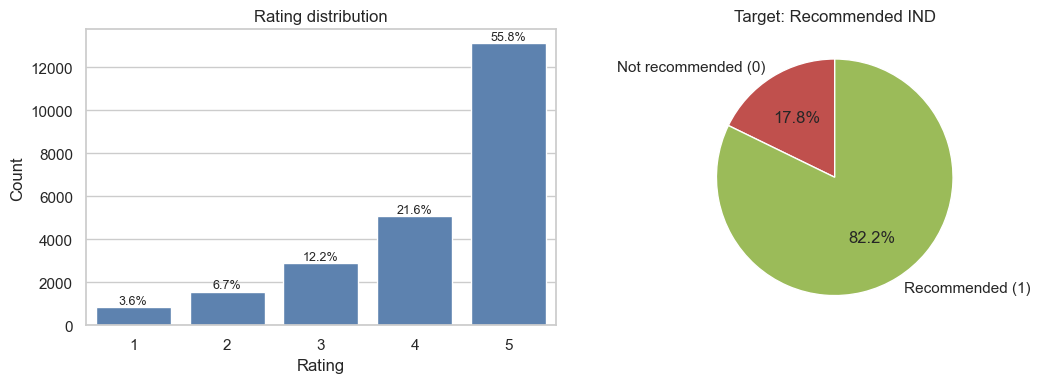

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
rc = df["Rating"].value_counts().sort_index()
sns.barplot(x=rc.index, y=rc.values, ax=ax[0], color="#4f81bd")
for i, v in enumerate(rc.values):
    ax[0].text(i, v + 150, f"{v/len(df)*100:.1f}%", ha="center", fontsize=9)
ax[0].set_title("Rating distribution")
ax[0].set_xlabel("Rating")
ax[0].set_ylabel("Count")
tc = df["Recommended IND"].value_counts().sort_index()
ax[1].pie(
    tc.values,
    labels=["Not recommended (0)", "Recommended (1)"],
    autopct="%1.1f%%",
    colors=["#c0504d", "#9bbb59"],
    startangle=90,
)
ax[1].set_title("Target: Recommended IND")
savefig("02_rating_and_target.png")
results["rating_counts"] = {int(k): int(v) for k, v in rc.items()}
results["target_counts"] = {int(k): int(v) for k, v in tc.items()}

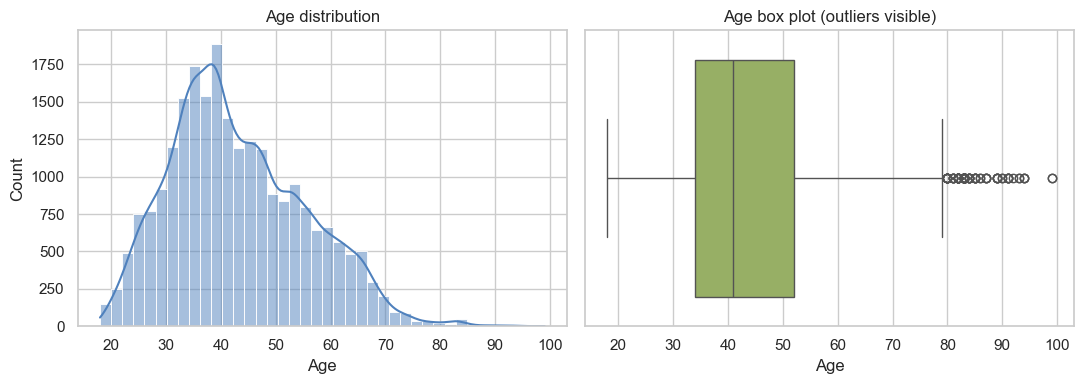

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["Age"], bins=40, kde=True, ax=ax[0], color="#4f81bd")
ax[0].set_title("Age distribution")
sns.boxplot(x=df["Age"], ax=ax[1], color="#9bbb59")
ax[1].set_title("Age box plot (outliers visible)")
savefig("03_age_distribution.png")

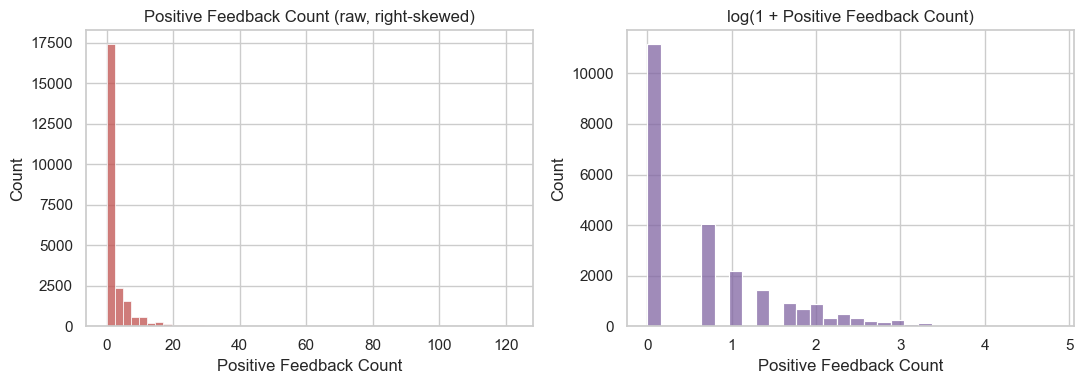

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["Positive Feedback Count"], bins=50, ax=ax[0], color="#c0504d")
ax[0].set_title("Positive Feedback Count (raw, right-skewed)")
sns.histplot(
    np.log1p(df["Positive Feedback Count"]), bins=30, ax=ax[1], color="#8064a2"
)
ax[1].set_title("log(1 + Positive Feedback Count)")
savefig("04_positive_feedback.png")

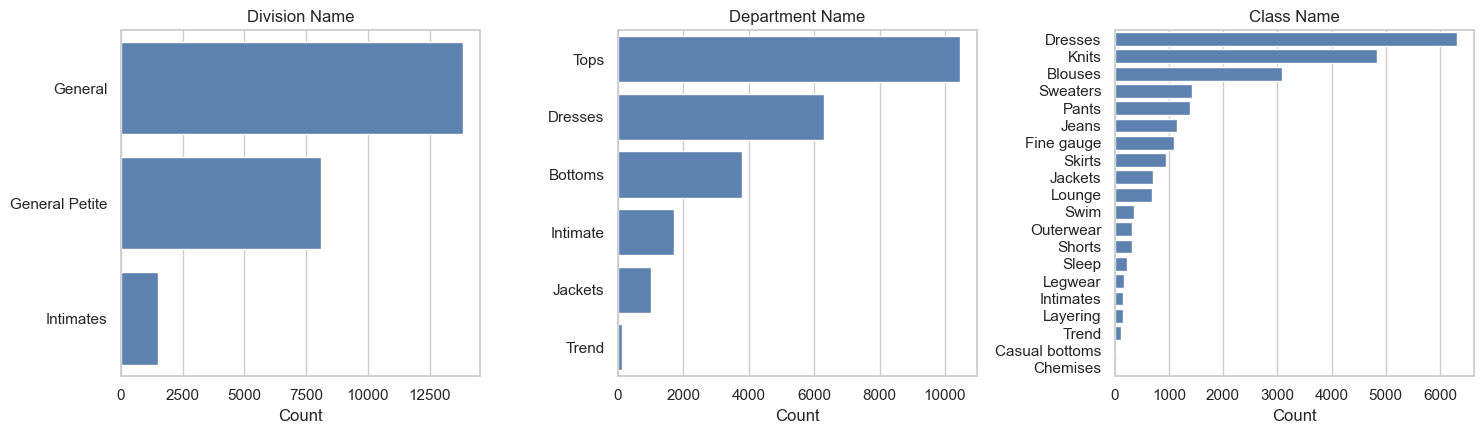

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for a, col in zip(ax, ["Division Name", "Department Name", "Class Name"]):
    order = df[col].value_counts().index
    sns.countplot(y=col, data=df, order=order, ax=a, color="#4f81bd")
    a.set_title(f"{col}")
    a.set_xlabel("Count")
    a.set_ylabel("")
savefig("05_categorical_counts.png")

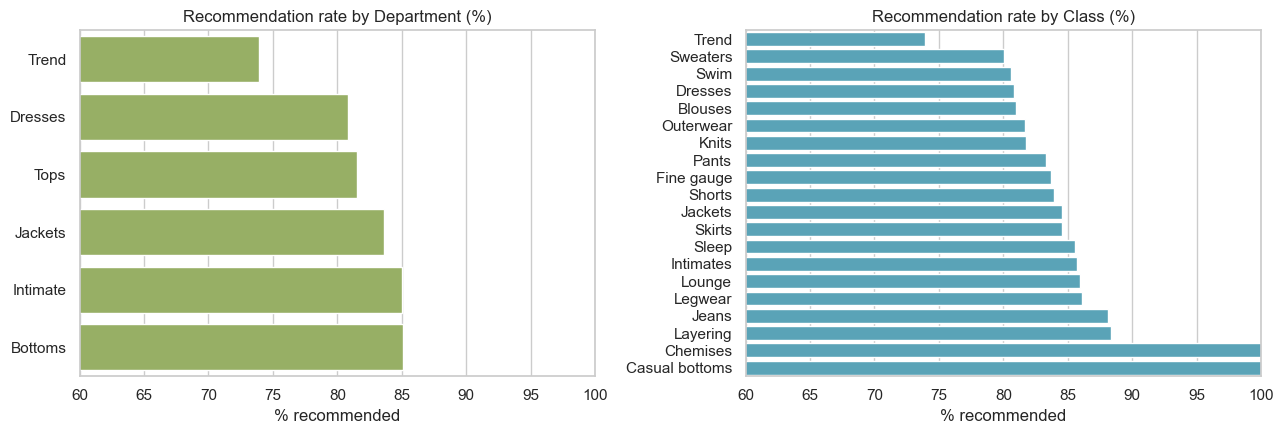

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
rec_dept = df.groupby("Department Name")["Recommended IND"].mean().sort_values()
sns.barplot(x=rec_dept.values * 100, y=rec_dept.index, ax=ax[0], color="#9bbb59")
ax[0].set_title("Recommendation rate by Department (%)")
ax[0].set_xlabel("% recommended")
ax[0].set_ylabel("")
ax[0].set_xlim(60, 100)
rec_class = df.groupby("Class Name")["Recommended IND"].mean().sort_values()
sns.barplot(x=rec_class.values * 100, y=rec_class.index, ax=ax[1], color="#4bacc6")
ax[1].set_title("Recommendation rate by Class (%)")
ax[1].set_xlabel("% recommended")
ax[1].set_ylabel("")
ax[1].set_xlim(60, 100)
savefig("06_recommendation_rate.png")
results["rec_by_dept"] = (rec_dept * 100).round(1).to_dict()
results["rec_by_class"] = (rec_class * 100).round(1).to_dict()

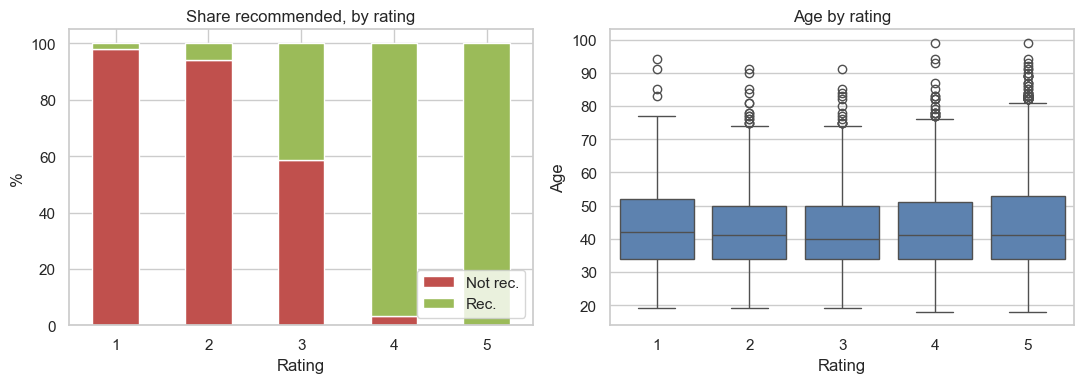

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ct = pd.crosstab(df["Rating"], df["Recommended IND"], normalize="index") * 100
ct.plot(kind="bar", stacked=True, ax=ax[0], color=["#c0504d", "#9bbb59"])
ax[0].set_title("Share recommended, by rating")
ax[0].set_ylabel("%")
ax[0].legend(["Not rec.", "Rec."], loc="lower right")
ax[0].tick_params(axis="x", rotation=0)
sns.boxplot(x="Rating", y="Age", data=df, ax=ax[1], color="#4f81bd")
ax[1].set_title("Age by rating")
savefig("07_rating_vs_recommend.png")
results["rec_share_by_rating"] = ct[1].round(1).to_dict()

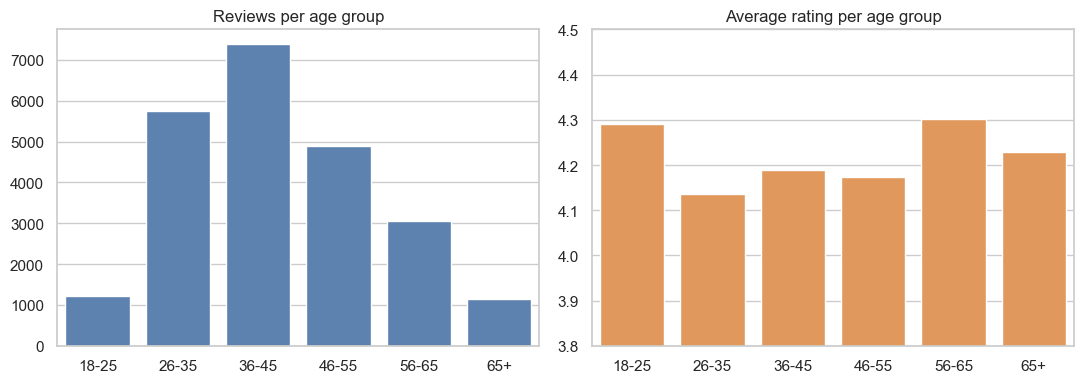

In [18]:
df["age_group"] = pd.cut(
    df["Age"],
    bins=[17, 25, 35, 45, 55, 65, 100],
    labels=["18-25", "26-35", "36-45", "46-55", "56-65", "65+"],
)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ag = df["age_group"].value_counts().sort_index()
sns.barplot(x=ag.index.astype(str), y=ag.values, ax=ax[0], color="#4f81bd")
ax[0].set_title("Reviews per age group")
ax[0].set_xlabel("")
agr = df.groupby("age_group")["Rating"].mean()
sns.barplot(x=agr.index.astype(str), y=agr.values, ax=ax[1], color="#f79646")
ax[1].set_ylim(3.8, 4.5)
ax[1].set_title("Average rating per age group")
ax[1].set_xlabel("")
savefig("08_age_groups.png")
results["avg_rating_by_age_group"] = {
    str(k): round(float(v), 3) for k, v in agr.items()
}
results["reviews_by_age_group"] = {str(k): int(v) for k, v in ag.items()}

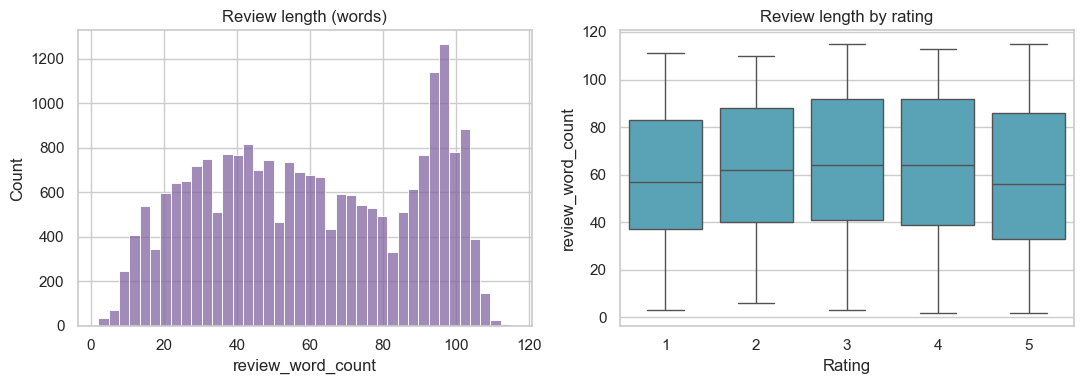

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(
    df.loc[df.has_review_text == 1, "review_word_count"],
    bins=40,
    ax=ax[0],
    color="#8064a2",
)
ax[0].set_title("Review length (words)")
sns.boxplot(
    x="Rating",
    y="review_word_count",
    data=df[df.has_review_text == 1],
    ax=ax[1],
    color="#4bacc6",
)
ax[1].set_title("Review length by rating")
savefig("09_review_length.png")

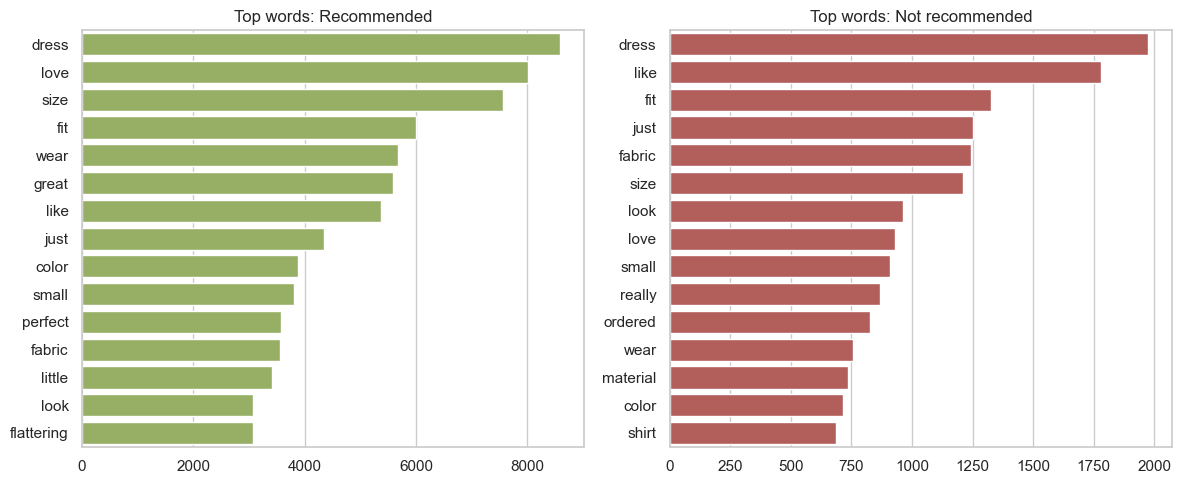

In [20]:
def top_words(texts, n=15):
    cv = CountVectorizer(stop_words="english", max_features=2000)
    X = cv.fit_transform(texts)
    freq = np.asarray(X.sum(axis=0)).ravel()
    idx = freq.argsort()[::-1][:n]
    return [(cv.get_feature_names_out()[i], int(freq[i])) for i in idx]


tw_pos = top_words(
    df.loc[(df["Recommended IND"] == 1) & (df.has_review_text == 1), "clean_review"]
)
tw_neg = top_words(
    df.loc[(df["Recommended IND"] == 0) & (df.has_review_text == 1), "clean_review"]
)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, tw, t, c in [
    (ax[0], tw_pos, "Recommended", "#9bbb59"),
    (ax[1], tw_neg, "Not recommended", "#c0504d"),
]:
    w, f = zip(*tw)
    sns.barplot(x=list(f), y=list(w), ax=a, color=c)
    a.set_title(f"Top words: {t}")
savefig("10_top_words.png")
results["top_words_pos"] = tw_pos[:8]
results["top_words_neg"] = tw_neg[:8]

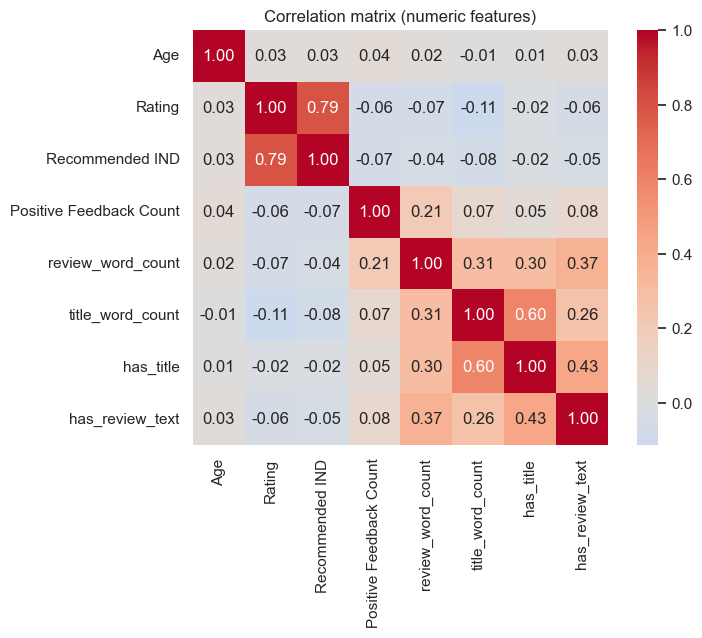

In [21]:
corr_cols = [
    "Age",
    "Rating",
    "Recommended IND",
    "Positive Feedback Count",
    "review_word_count",
    "title_word_count",
    "has_title",
    "has_review_text",
]
corr = df[corr_cols].corr()
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation matrix (numeric features)")
savefig("11_correlation_heatmap.png")
results["corr_rating_recommend"] = round(
    float(corr.loc["Rating", "Recommended IND"]), 3
)
results["corr_age_rating"] = round(float(corr.loc["Age", "Rating"]), 3)
results["corr_len_rating"] = round(float(corr.loc["review_word_count", "Rating"]), 3)

## 6. Outlier detection
Two standard methods are compared: **IQR rule** (below Q1 - 1.5*IQR or above Q3 + 1.5*IQR) and **Z-score** (|z| > 3).
* `Age`: roughly bell shaped, so IQR is applied directly.
* `Positive Feedback Count`: extremely right-skewed (skew > 6). Applying the plain IQR rule would delete about 9% of all rows that are genuine reviews. So the rule is applied on `log(1+x)`, which is the usual fix for skewed counts.
* Review length: checked as well.

In [22]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    i = q3 - q1
    return q1 - k * i, q3 + k * i


df["log_pos_feedback"] = np.log1p(df["Positive Feedback Count"])
checks = {
    "Age": "Age",
    "Positive Feedback Count (raw)": "Positive Feedback Count",
    "log(1+Positive Feedback Count)": "log_pos_feedback",
    "review_word_count": "review_word_count",
    "review_char_len": "review_char_len",
}
rows = []
for name, c in checks.items():
    lo, hi = iqr_bounds(df[c])
    n_iqr = int(((df[c] < lo) | (df[c] > hi)).sum())
    z = (df[c] - df[c].mean()) / df[c].std()
    n_z = int((z.abs() > 3).sum())
    rows.append(
        {
            "feature": name,
            "IQR lower": round(float(lo), 2),
            "IQR upper": round(float(hi), 2),
            "IQR outliers": n_iqr,
            "Z-score outliers": n_z,
        }
    )
out_tbl = pd.DataFrame(rows)
print(out_tbl.to_string(index=False))
results["outlier_table"] = rows

                       feature  IQR lower  IQR upper  IQR outliers  Z-score outliers
                           Age       7.00      79.00           109                99
 Positive Feedback Count (raw)      -4.50       7.50          2147               430
log(1+Positive Feedback Count)      -2.08       3.47           154               172
             review_word_count     -45.50     166.50             0                 0
               review_char_len    -241.50     866.50             0                 0


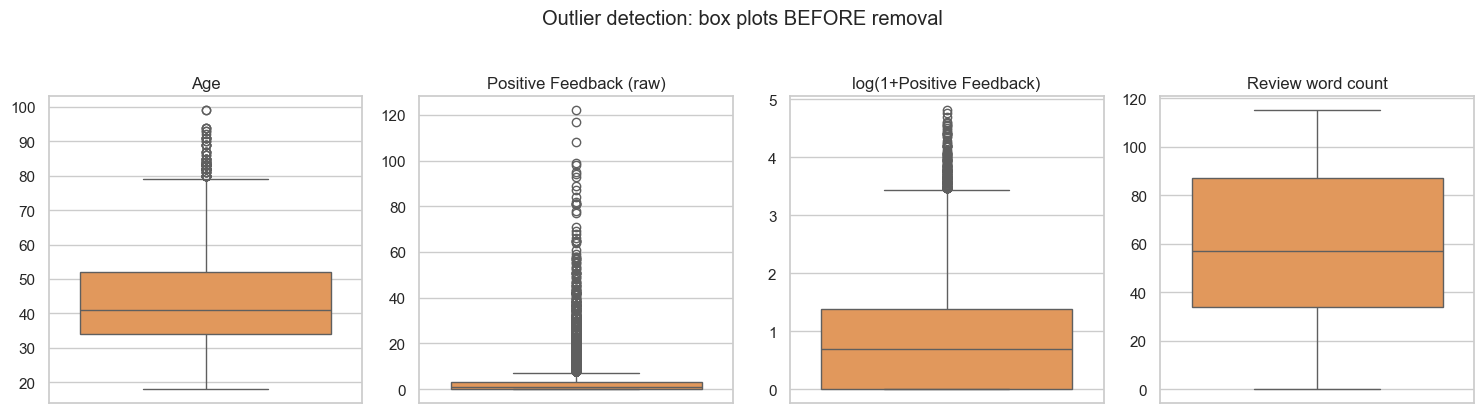

In [23]:
fig, ax = plt.subplots(1, 4, figsize=(15, 4))
for a, (c, t) in zip(
    ax,
    [
        ("Age", "Age"),
        ("Positive Feedback Count", "Positive Feedback (raw)"),
        ("log_pos_feedback", "log(1+Positive Feedback)"),
        ("review_word_count", "Review word count"),
    ],
):
    sns.boxplot(y=df[c], ax=a, color="#f79646")
    a.set_title(t)
    a.set_ylabel("")
plt.suptitle("Outlier detection: box plots BEFORE removal", y=1.03)
savefig("12_outliers_before.png")

## 7. Outlier removal
Rows flagged by the IQR rule on `Age` and on `log(1+Positive Feedback Count)` are removed. Review length is also checked; if it has no outliers, nothing is removed for it.

Age outliers: 109 | Pos. feedback outliers: 154 | Length outliers: 0 | total removed (union): 263
Shape after outlier removal: (23188, 18)


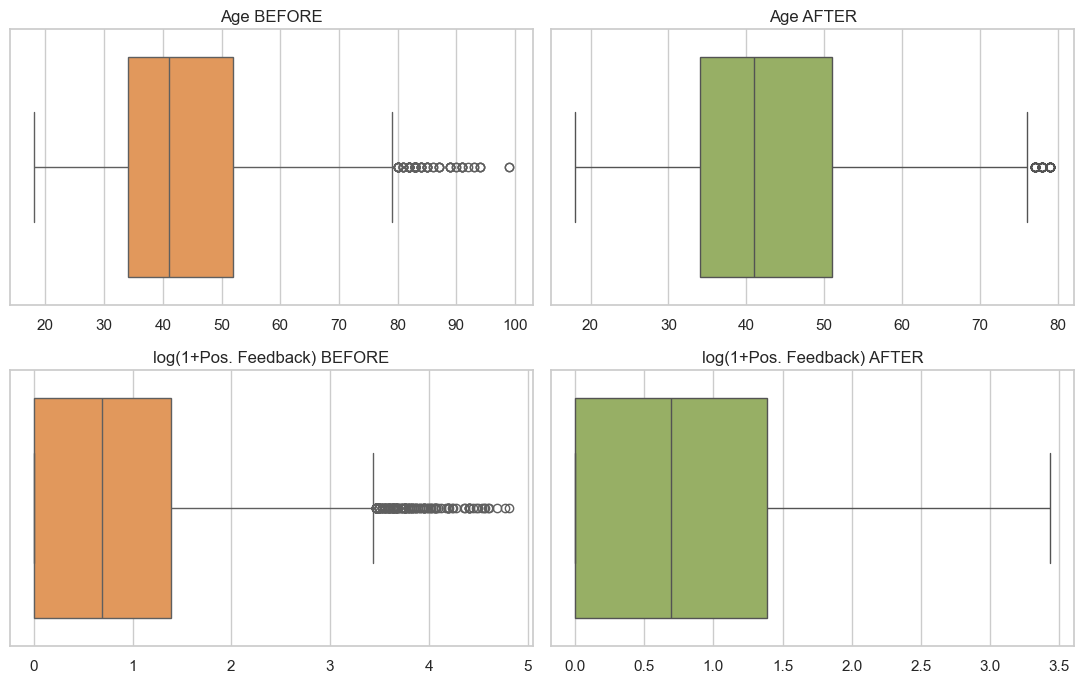

In [24]:
age_lo, age_hi = iqr_bounds(df["Age"])
pf_lo, pf_hi = iqr_bounds(df["log_pos_feedback"])
len_lo, len_hi = iqr_bounds(df["review_word_count"])
mask_age = (df["Age"] < age_lo) | (df["Age"] > age_hi)
mask_pf = (df["log_pos_feedback"] < pf_lo) | (df["log_pos_feedback"] > pf_hi)
mask_len = (df["review_word_count"] < len_lo) | (df["review_word_count"] > len_hi)
remove = mask_age | mask_pf | mask_len
print(
    f"Age outliers: {mask_age.sum()} | Pos. feedback outliers: {mask_pf.sum()} | "
    f"Length outliers: {mask_len.sum()} | total removed (union): {remove.sum()}"
)
results["removed"] = {
    "age": int(mask_age.sum()),
    "pos_feedback": int(mask_pf.sum()),
    "length": int(mask_len.sum()),
    "total": int(remove.sum()),
    "age_bounds": [round(float(age_lo), 1), round(float(age_hi), 1)],
    "pf_bounds_log": [round(float(pf_lo), 2), round(float(pf_hi), 2)],
    "pf_upper_raw": round(float(np.expm1(pf_hi)), 1),
}
df_before = df.copy()
df_clean = df.loc[~remove].reset_index(drop=True)
results["shape_after_outliers"] = list(df_clean.shape)
results["target_before_rate"] = round(float(df["Recommended IND"].mean()), 3)
results["target_after_rate"] = round(float(df_clean["Recommended IND"].mean()), 3)
print("Shape after outlier removal:", df_clean.shape)

fig, ax = plt.subplots(2, 2, figsize=(11, 7))
sns.boxplot(x=df_before["Age"], ax=ax[0, 0], color="#f79646")
ax[0, 0].set_title("Age BEFORE")
sns.boxplot(x=df_clean["Age"], ax=ax[0, 1], color="#9bbb59")
ax[0, 1].set_title("Age AFTER")
sns.boxplot(x=df_before["log_pos_feedback"], ax=ax[1, 0], color="#f79646")
ax[1, 0].set_title("log(1+Pos. Feedback) BEFORE")
sns.boxplot(x=df_clean["log_pos_feedback"], ax=ax[1, 1], color="#9bbb59")
ax[1, 1].set_title("log(1+Pos. Feedback) AFTER")
for a in ax.ravel():
    a.set_xlabel("")
savefig("13_outliers_before_after.png")

## 8. Encoding categorical variables
* `Division Name`, `Department Name`, `Class Name`: nominal with no order, so **one-hot encoding** (`drop_first=True` to avoid the dummy-variable trap).
* `Clothing ID`: an identifier with ~1,200 unique values; one-hot would explode the feature count, so it is dropped (a frequency feature `product_review_count` is kept instead).
* `Rating` is ordinal (1 to 5) and already numeric, so it is kept as it is.
* `Title`, `Review Text`: raw text is kept aside for the NLP stage (TF-IDF / embeddings) in the next review.

In [25]:
df_clean["product_review_count"] = df_clean.groupby("Clothing ID")[
    "Clothing ID"
].transform("count")
cat_cols = ["Division Name", "Department Name", "Class Name"]
df_enc = pd.get_dummies(df_clean, columns=cat_cols, drop_first=True, dtype=int)
print("Columns after encoding:", df_enc.shape[1])
results["n_onehot"] = int(
    sum(
        c.startswith(("Division Name_", "Department Name_", "Class Name_"))
        for c in df_enc.columns
    )
)

Columns after encoding: 42


## 9. Train/test split, then scaling and standardization
The split is done **before** fitting any scaler, so test data never influences the scaler (prevents data leakage). The split is stratified on the target.
* **Standardization** (`StandardScaler`, mean 0, std 1) is the main version, used for models like Logistic Regression, SVM, KNN and neural networks.
* **Min-Max scaling** (`MinMaxScaler`, range 0 to 1) is also produced for comparison.
* `Positive Feedback Count` and `product_review_count` are log-transformed first to reduce skew.

In [26]:
df_enc["log_product_review_count"] = np.log1p(df_enc["product_review_count"])
scale_cols = [
    "Age",
    "log_pos_feedback",
    "review_word_count",
    "review_char_len",
    "title_word_count",
    "log_product_review_count",
]
drop_cols = [
    "Clothing ID",
    "Title",
    "Review Text",
    "clean_review",
    "age_group",
    "Positive Feedback Count",
    "product_review_count",
]
X = df_enc.drop(columns=drop_cols + ["Recommended IND"])
y = df_enc["Recommended IND"]
text_df = df_enc[["Title", "Review Text", "clean_review"]]

X_train, X_test, y_train, y_test, txt_train, txt_test = train_test_split(
    X, y, text_df, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "Test:", X_test.shape)
results["split"] = {
    "train": list(X_train.shape),
    "test": list(X_test.shape),
    "train_pos_rate": round(float(y_train.mean()), 3),
    "test_pos_rate": round(float(y_test.mean()), 3),
}

std = StandardScaler().fit(X_train[scale_cols])
mm = MinMaxScaler().fit(X_train[scale_cols])
X_train_std, X_test_std = X_train.copy(), X_test.copy()
X_train_mm, X_test_mm = X_train.copy(), X_test.copy()
X_train_std[scale_cols] = std.transform(X_train[scale_cols])
X_test_std[scale_cols] = std.transform(X_test[scale_cols])
X_train_mm[scale_cols] = mm.transform(X_train[scale_cols])
X_test_mm[scale_cols] = mm.transform(X_test[scale_cols])

chk = pd.DataFrame(
    {
        "mean_std": X_train_std[scale_cols].mean(),
        "std_std": X_train_std[scale_cols].std(),
        "min_mm": X_train_mm[scale_cols].min(),
        "max_mm": X_train_mm[scale_cols].max(),
    }
).round(3)
print(chk)
results["scaling_check"] = chk.to_dict("index")
results["scale_cols"] = scale_cols

Train: (18550, 35) Test: (4638, 35)
                          mean_std  std_std  min_mm  max_mm
Age                           -0.0      1.0     0.0     1.0
log_pos_feedback               0.0      1.0     0.0     1.0
review_word_count             -0.0      1.0     0.0     1.0
review_char_len               -0.0      1.0     0.0     1.0
title_word_count              -0.0      1.0     0.0     1.0
log_product_review_count      -0.0      1.0     0.0     1.0


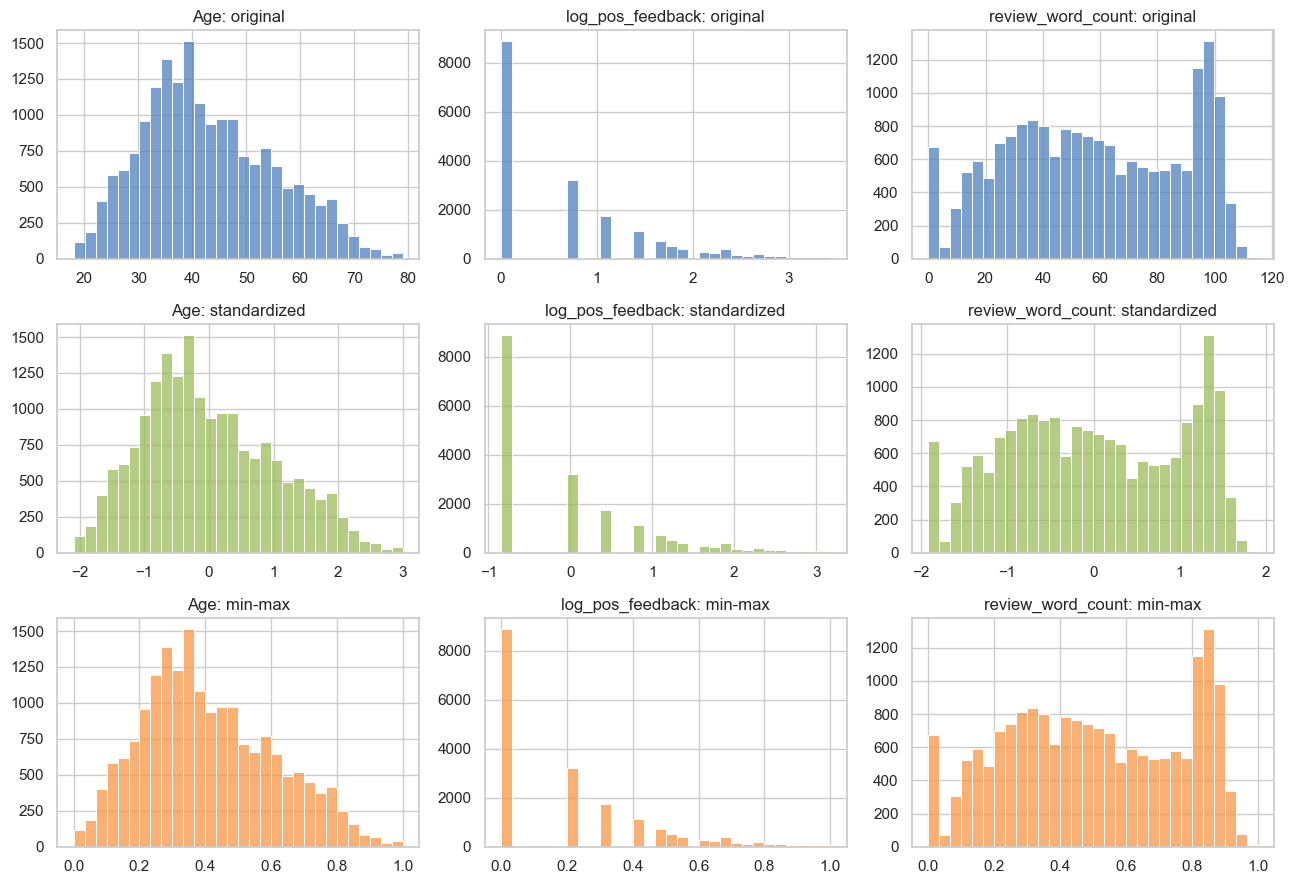

In [27]:
fig, ax = plt.subplots(3, 3, figsize=(13, 9))
for j, c in enumerate(["Age", "log_pos_feedback", "review_word_count"]):
    sns.histplot(X_train[c], bins=30, ax=ax[0, j], color="#4f81bd")
    ax[0, j].set_title(f"{c}: original")
    sns.histplot(X_train_std[c], bins=30, ax=ax[1, j], color="#9bbb59")
    ax[1, j].set_title(f"{c}: standardized")
    sns.histplot(X_train_mm[c], bins=30, ax=ax[2, j], color="#f79646")
    ax[2, j].set_title(f"{c}: min-max")
    for i in range(3):
        ax[i, j].set_xlabel("")
        ax[i, j].set_ylabel("")
savefig("14_scaling_comparison.png")

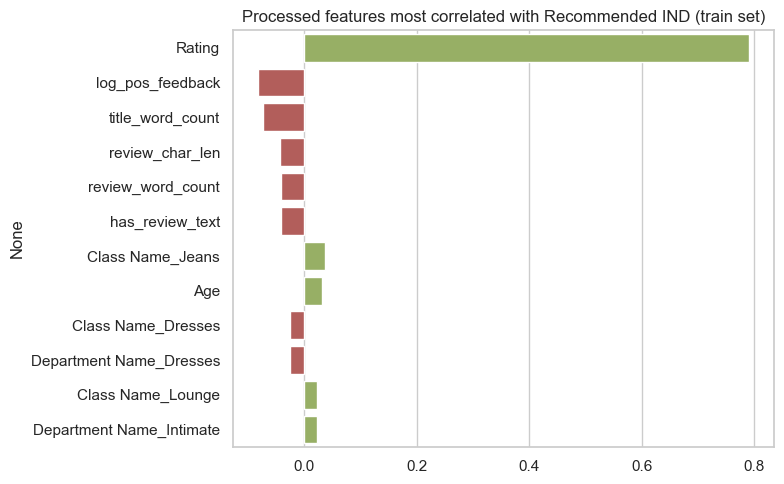

In [28]:
corr_t = (
    pd.concat([X_train_std, y_train], axis=1)
    .corr()["Recommended IND"]
    .drop("Recommended IND")
)
top = corr_t.reindex(corr_t.abs().sort_values(ascending=False).index).head(12)
plt.figure(figsize=(8, 5))
sns.barplot(
    x=top.values,
    y=top.index,
    palette=["#9bbb59" if v > 0 else "#c0504d" for v in top.values],
)
plt.title("Processed features most correlated with Recommended IND (train set)")
savefig("15_feature_target_correlation.png")
results["top_corr_target"] = top.round(3).head(6).to_dict()

## 10. Save processed data

In [29]:
pd.concat([X_train_std, y_train], axis=1).to_csv(
    OUT_DIR / "train_standardized.csv", index=False
)
pd.concat([X_test_std, y_test], axis=1).to_csv(
    OUT_DIR / "test_standardized.csv", index=False
)
pd.concat([X_train_mm, y_train], axis=1).to_csv(
    OUT_DIR / "train_minmax.csv", index=False
)
pd.concat([X_test_mm, y_test], axis=1).to_csv(OUT_DIR / "test_minmax.csv", index=False)
pd.concat([txt_train, y_train], axis=1).to_csv(OUT_DIR / "train_text.csv", index=False)
pd.concat([txt_test, y_test], axis=1).to_csv(OUT_DIR / "test_text.csv", index=False)
df_clean.to_csv(OUT_DIR / "cleaned_after_outlier_removal.csv", index=False)
results["final_feature_count"] = int(X_train_std.shape[1])
with open(OUT_DIR / "results_summary.json", "w") as f:
    json.dump(results, f, indent=2, default=str)
print("Done. Final feature count:", X_train_std.shape[1])

Done. Final feature count: 35
